# EDA: Indonesian extractive MRC (SQuAD v2 style)

Loads `data/processed/`: `train`, `dev` and their `slices_*` metadata.

`itest` is the internal sealed test (see `docs/CONTRACT.md`): it is deliberately **not loaded** here.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)

def find_root(p=Path.cwd()):
    for d in [p, *p.parents]:
        if (d / "data" / "processed").is_dir():
            return d
    raise FileNotFoundError("data/processed not found")

DATA = find_root() / "data" / "processed"
SPLITS = ["train", "dev"]  # itest stays sealed

def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

raw = {s: pd.DataFrame(load_jsonl(DATA / f"{s}.jsonl")) for s in SPLITS}
slices = {s: pd.DataFrame(load_jsonl(DATA / f"slices_{s}.jsonl")) for s in SPLITS}
for s in SPLITS:
    print(s, raw[s].shape, slices[s].shape)

train (6435, 5) (6435, 18)
dev (803, 5) (803, 18)


In [2]:
# Merge raw examples with their slice metadata on id
dfs = []
for s in SPLITS:
    d = raw[s].merge(slices[s].drop(columns=["is_impossible"]), on="id", validate="1:1")
    d["split"] = s
    # answers -> plain list of strings; keep offsets separately for highlighting
    d["answer_starts"] = d["answers"].map(lambda a: [x["answer_start"] for x in a])
    d["answers"] = d["answers"].map(lambda a: [x["text"] for x in a])
    d["answer_text"] = d["answers"].map(lambda a: a[0] if a else "")
    dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
df[["question", "answers", "answer_starts", "is_impossible"]].head(3)

,question,answers,answer_starts,is_impossible
0,Kapan internet pertama masuk ke Indonesia?,[1990-an],[51],False
1,Siapa penulis komik Marvel ?,[Stan Lee],[0],False
2,Kapan Archimedes dipisahkan oleh ayahnya?,[],[],True


## Sizes and answerability

In [3]:
summary = df.groupby("split").agg(
    n=("id", "size"),
    n_contexts=("context", "nunique"),
    pct_unanswerable=("is_impossible", "mean"),
)
summary["pct_unanswerable"] = (summary["pct_unanswerable"] * 100).round(1)
summary

,n,n_contexts,pct_unanswerable
split,,,
dev,803,291,46.2
train,6435,2633,43.9


## Lengths

split                       dev        train
ctx_len_words count  803.000000  6435.000000
              mean    79.480697    83.008081
              std     46.327879    72.160428
              min     10.000000     5.000000
              25%     48.000000    49.000000
              50%     68.000000    71.000000
              75%    102.000000   103.000000
              max    294.000000  2798.000000
q_len_words   count  803.000000  6435.000000
              mean     5.737235     5.624553
              std      2.162811     1.882751
              min      3.000000     2.000000
              25%      4.000000     4.000000
              50%      5.000000     5.000000
              75%      7.000000     7.000000
              max     23.000000    22.000000
ans_len_words count  803.000000  6435.000000
              mean     2.686177     2.902253
              std      5.895063     5.513252
              min      0.000000     0.000000
              25%      0.000000     0.000000
              50%      1.000000     1.000000
              75%      3.000000     3.000000
              max     67.000000    61.000000

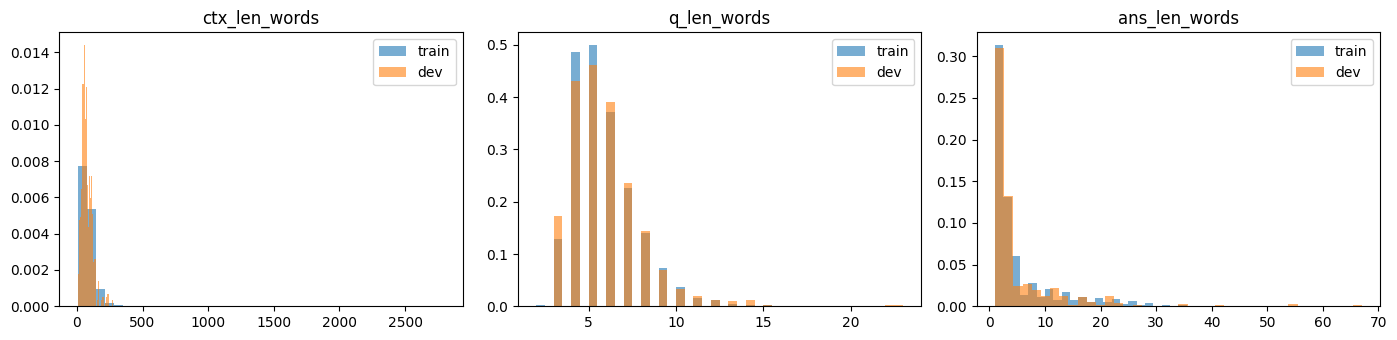

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for i, c in enumerate(["ctx_len_words", "q_len_words", "ans_len_words"]):
    for s in SPLITS:
        sub = df[(df.split == s)]
        if c == "ans_len_words":
            sub = sub[~sub.is_impossible]
        ax[i].hist(sub[c], bins=40, alpha=.6, density=True, label=s)
    ax[i].set_title(c); ax[i].legend()
plt.tight_layout()
df.groupby("split")[["ctx_len_words", "q_len_words", "ans_len_words"]].describe().T

## Question types

In [5]:
for col in ["q_word", "q_type"]:
    ct = pd.crosstab(df[col], df["split"], normalize="columns").mul(100).round(1)
    display(ct.sort_values("train", ascending=False).head(15))
(pd.crosstab(df["q_type"], df["is_impossible"], normalize="index").mul(100).round(1)
 .rename(columns={False: "answerable %", True: "unanswerable %"}))

split,dev,train
q_word,,
apa,34.6,31.7
kapan,24.2,20.3
siapa,17.2,16.1
berapa,12.7,16.0
mana,3.9,5.7
dimana,3.5,5.1
mengapa,1.2,1.3
bagaimana,1.4,1.3
ada,0.1,1.2


split,dev,train
q_type,,
entity_or_def,35.0,32.6
time,26.2,21.9
person,16.9,15.9
number,11.3,15.8
location,7.6,10.1
other,3.0,3.4
yesno_like,0.0,0.3


is_impossible,answerable %,unanswerable %
q_type,,
entity_or_def,58.9,41.1
location,57.0,43.0
number,56.4,43.6
other,43.2,56.8
person,55.7,44.3
time,52.1,47.9
yesno_like,75.0,25.0


## Answer characteristics (answerable only)

split,dev,train
ans_type,,
date_year,20.4,17.6
lowercase_phrase,27.5,31.2
number,7.9,10.6
other_cap,28.0,23.9
person_like_cap,16.2,16.8


split,dev,train
ans_len_bucket,,
1,30.8,26.3
2-3,37.5,40.3
4-6,10.6,11.0
>6,21.1,22.4


split,dev,train
ans_rel_pos_bucket,,
Q1,51.2,51.9
Q2,25.9,22.8
Q3,11.1,14.9
Q4,11.8,10.4


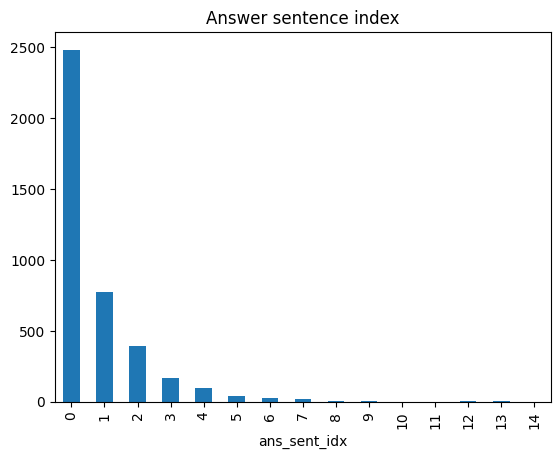

In [6]:
has = df[~df.is_impossible]
for col in ["ans_type", "ans_len_bucket", "ans_rel_pos_bucket"]:
    display(pd.crosstab(has[col], has["split"], normalize="columns").mul(100).round(1))
has.ans_sent_idx.value_counts().sort_index().head(15).plot.bar(title="Answer sentence index")
plt.show()

## Lexical overlap (question vs context)

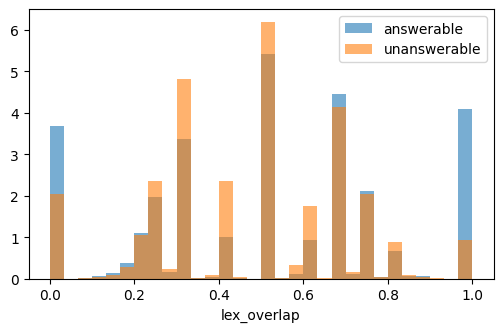

,size,mean
lex_overlap_bucket,,
high,1406,0.317
low,2629,0.442
mid,3203,0.497


In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for flag, g in df.groupby("is_impossible"):
    ax.hist(g["lex_overlap"], bins=30, alpha=.6, density=True,
            label="unanswerable" if flag else "answerable")
ax.set_xlabel("lex_overlap"); ax.legend()
plt.show()
df.groupby("lex_overlap_bucket")["is_impossible"].agg(["size", "mean"]).round(3)

## Other slices and context reuse

In [8]:
for col in ["ctx_len_bucket", "has_citation", "n_gold"]:
    display(df.groupby(col)["is_impossible"].agg(n="size", pct_impossible="mean").round(3))
df.groupby(["split", "context"]).size().groupby("split").describe()

,n,pct_impossible
ctx_len_bucket,,
120-250,1046,0.459
60-120,3317,0.443
<60,2800,0.435
>250,75,0.427


,n,pct_impossible
has_citation,,
False,4559,0.442
True,2679,0.441


,n,pct_impossible
n_gold,,
0,3198,1.0
1,3980,0.0
2,60,0.0


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
dev,291.0,2.75945,2.713416,1.0,2.0,2.0,3.0,35.0
train,2633.0,2.44398,1.941976,1.0,2.0,2.0,2.0,29.0


## Sanity checks

In [9]:
# answer_start must point at the answer text in the context
bad = [r.id for r in df.itertuples()
       for t, st in zip(r.answers, r.answer_starts)
       if r.context[st:st + len(t)] != t]
print("misaligned spans:", len(bad))
# context overlap between train and dev (should be 0 since splits are grouped by context)
print("shared contexts train/dev:", len(set(raw["train"].context) & set(raw["dev"].context)))
print("duplicate ids:", df.id.duplicated().sum())

misaligned spans: 0
shared contexts train/dev: 0
duplicate ids: 0


## Random examples

In [10]:
df[["split", "question", "answer_text", "is_impossible"]].sample(8, random_state=0)

,split,question,answer_text,is_impossible
6933,dev,apakah yang dimaksud dengan toksikologi ?,pemahaman mengenai pengaruh-pengaruh bahan kimia yang merugikan bagi organisme hidup,False
6577,dev,Berapa luas wilayah Laut Hitam?,422.000km²,False
6019,train,Kapan Kamen Rider pertama diproduksi ?,3 April 1971,False
5854,train,Siapakah istri Habib Bahar bin Smith?,Fadlun Faisal Balghoits,False
2092,train,ada berapakah jenis semut ?,12.000,False
5024,train,Di kota mana markas Liverpool F.C?,Kota Liverpool,False
1453,train,apakah penyebab kematian Edward Gierek?,penyakit paru-paru,False
6560,dev,Siapa yang mendukung tabel non- periodik?,,True


## Highlighted examples

- **green**: gold answer span(s) in the context
- **yellow**: any context word that also appears in the question (case-insensitive, all words including stopwords)
- **orange** (in the question): any question word that does not occur anywhere in the context. Exact surface match, so inflected forms (e.g. *didirikan* vs *berdiri*) and paraphrases also show orange; that is the point, it flags the words the model must bridge.

Green wins where they overlap. Rendered as HTML so it works in Jupyter/VS Code (colorama only emits ANSI codes for terminals).

In [11]:
import re, html, random
from IPython.display import HTML, display

GREEN, YELLOW, ORANGE = "#8be28b", "#fff176", "#ffb74d"
WORD = re.compile(r"\w+", re.UNICODE)

def highlight(context, question, answers, starts):
    q_words = {w.lower() for w in WORD.findall(question)}
    color = [None] * len(context)
    for m in WORD.finditer(context):
        if m.group().lower() in q_words:
            for i in range(m.start(), m.end()):
                color[i] = YELLOW
    for t, st in zip(answers, starts):          # answers override yellow
        for i in range(st, min(st + len(t), len(context))):
            color[i] = GREEN
    out, i = [], 0
    while i < len(context):
        j = i
        while j < len(context) and color[j] == color[i]:
            j += 1
        seg = html.escape(context[i:j])
        out.append(f'<mark style="background:{color[i]};color:#000">{seg}</mark>' if color[i] else seg)
        i = j
    return "".join(out)

def highlight_question(question, context):
    """Orange = question word that does not occur anywhere in the context (same tokenizer, case-insensitive)."""
    c_words = {w.lower() for w in WORD.findall(context)}
    out, last = [], 0
    for m in WORD.finditer(question):
        out.append(html.escape(question[last:m.start()]))
        w = html.escape(m.group())
        out.append(f'<mark style="background:{ORANGE};color:#000">{w}</mark>' if m.group().lower() not in c_words else w)
        last = m.end()
    out.append(html.escape(question[last:]))
    return "".join(out)

def show(rows):
    parts = []
    for n, r in enumerate(rows.itertuples(), 1):
        tag = "UNANSWERABLE" if r.is_impossible else "answerable"
        parts.append(
            f'<div style="margin:0 0 14px;padding:8px;border:1px solid #888;border-radius:6px">'
            f'<b>{n}. [{r.split}] {highlight_question(r.question, r.context)}</b> <i>({tag})</i><br>'
            f'<small>answers: {html.escape(repr(r.answers))}</small><br>'
            f'{highlight(r.context, r.question, r.answers, r.answer_starts)}</div>')
    display(HTML("".join(parts)))

sample = df.sample(20, random_state=0)   # change random_state to see other rows
show(sample)